# Translating and testing MoSiC in OpenMM

## Initial loading and ParmED

In [ ]:
import parmed as pmd
from parmed import load_file
from parmed.openmm.reporters import NetCDFReporter
from parmed import unit as u
import os
os.environ['GMXLIB'] = "/scratch/midway3/gruschka/toid_explore/forcefields/"
GROMACS_FILE_LOC = "../toid_explore/simulations/A+C/AAAAA/4_pb"
gro_file = f"{GROMACS_FILE_LOC}/md.gro"
top_file = f"{GROMACS_FILE_LOC}/topol.top"


In [ ]:

gmx_top = pmd.load_file(top_file, xyz=gro_file, includeDir=[os.environ['GMXLIB'], GROMACS_FILE_LOC], defines={'POSRES' : True})
gmx_top.save("test.prmtop", overwrite=True)
gmx_top.save("test.inpcrd", overwrite=True)
gmx_top.save("test.gro", overwrite=True)
gmx_top.save("test.top", overwrite=True)

In [ ]:
import parmed as pmd
from parmed import load_file
from parmed.openmm.reporters import NetCDFReporter
from parmed import unit as u
import os
os.environ['GMXLIB'] = "/scratch/midway3/gruschka/toid_explore/forcefields/"
GROMACS_FILE_LOC = "../toid_explore/simulations/A+C/AAAAA/4_pb"
gro_file = f"{GROMACS_FILE_LOC}/md.gro"
top_file = f"{GROMACS_FILE_LOC}/topol.top"

gmx_top = pmd.load_file(top_file, xyz=gro_file, includeDir=[os.environ['GMXLIB'], GROMACS_FILE_LOC], defines={'POSRES' : True})
gmx_top.save("test.prmtop", overwrite=True)
gmx_top.save("test.inpcrd", overwrite=True)
gmx_top.save("test.gro", overwrite=True)
gmx_top.save("test.top", overwrite=True)

# Make XML

In [1]:
import glob
from parmed.gromacs import GromacsParameterSet

mosic_itps = ['/scratch/midway3/gruschka/toid_explore/forcefields/charmm36-feb2021.ff/forcefield.itp',
              '/scratch/midway3/gruschka/toid_explore/forcefields/charmm36-feb2021.ff/ffnonbonded.itp',
              '/scratch/midway3/gruschka/toid_explore/forcefields/charmm36-feb2021.ff/ffbonded.itp',
              '/scratch/midway3/gruschka/toid_explore/forcefields/charmm36-feb2021.ff/gb.itp',
              '/scratch/midway3/gruschka/toid_explore/forcefields/charmm36-feb2021.ff/cmap.itp',
              '/scratch/midway3/gruschka/toid_explore/forcefields/charmm36-feb2021.ff/nbfix.itp']
mosic_atps = ['/scratch/midway3/gruschka/toid_explore/forcefields/charmm36-feb2021.ff/atomtypes.atp']
mosic_rtps = ['/scratch/midway3/gruschka/toid_explore/forcefields/charmm36-feb2021.ff/merged.rtp']
files = mosic_itps + mosic_atps + mosic_rtps
params = GromacsParameterSet(*files)

# from parmed.gromacs.gromacstop import 

/scratch/midway3/gruschka/metal-toid/lib/python3.10/site-packages/parmed/topologyobjects.py:2803: ParameterWarning: Overriding DihedralType in DihedralTypeList with same periodicity
  warnings.warn('Overriding DihedralType in DihedralTypeList '
/scratch/midway3/gruschka/metal-toid/lib/python3.10/site-packages/parmed/topologyobjects.py:2803: ParameterWarning: Overriding DihedralType in DihedralTypeList with same periodicity
  warnings.warn('Overriding DihedralType in DihedralTypeList '


In [2]:
params.angle_types
params.write_xml("mosic.xml")

Wrote OpenMM XML force field to mosic.xml


In [3]:
water_itps = ['/scratch/midway3/gruschka/toid_explore/forcefields/charmm36-feb2021.ff/ions.itp','/scratch/midway3/gruschka/toid_explore/forcefields/charmm36-feb2021.ff/spce.itp']
water_files = water_itps
water_params = GromacsParameterSet(*water_files)
water_params.write_xml("spce_ions.xml")

Wrote OpenMM XML force field to spce_ions.xml


## Validating XML

In [6]:
import xml.etree.ElementTree as ET
import numpy as np

ref_tree = ET.parse('/scratch/midway3/gruschka/metal-toid/lib/python3.10/site-packages/openmm/app/data/charmm36_2024.xml')  # or find with openmm.app
mine_tree = ET.parse('mosic.xml')


### CMAP Torsion Force Matching

After some testing, we've gotten the parser to work, there was a convention difference between gromacs/openmm in storing the map definitions (0-2pi vs -pi/2-pi/2), phi-psi vs psi-phi, just needed to translate and transpose the matrix and now they match.

In [7]:
for name, tree in [('ref', ref_tree), ('mine', mine_tree)]:
    maps = tree.findall('.//CMAPTorsionForce/Map')
    torsions = tree.findall('.//CMAPTorsionForce/Torsion')
    print(f"\n{name}: {len(maps)} maps, {len(torsions)} torsions")
    for i, m in enumerate(maps):
        vals = [float(v) for v in m.text.split()]
        print(f"  Map {i}: {len(vals)} values, range [{min(vals):.2f}, {max(vals):.2f}]")
    for t in torsions:
        print(f"  Torsion: map={t.get('map')} "
              f"{t.get('class1')}-{t.get('class2')}-{t.get('class3')}-"
              f"{t.get('class4')}-{t.get('class5')}")


ref: 24 maps, 24 torsions
  Map 0: 576 values, range [-29.50, 28.20]
  Map 1: 576 values, range [-29.50, 28.20]
  Map 2: 576 values, range [-5.26, 50.96]
  Map 3: 576 values, range [-5.26, 50.96]
  Map 4: 576 values, range [-25.97, 15.50]
  Map 5: 576 values, range [-25.97, 15.50]
  Map 6: 576 values, range [-29.50, 28.20]
  Map 7: 576 values, range [-29.50, 28.20]
  Map 8: 576 values, range [-5.26, 50.96]
  Map 9: 576 values, range [-5.26, 50.96]
  Map 10: 576 values, range [-16.57, 20.33]
  Map 11: 576 values, range [-18.32, 28.61]
  Map 12: 576 values, range [-29.43, 28.21]
  Map 13: 576 values, range [-29.43, 28.21]
  Map 14: 576 values, range [-29.43, 28.21]
  Map 15: 576 values, range [-29.43, 28.21]
  Map 16: 576 values, range [-5.26, 50.96]
  Map 17: 576 values, range [-5.26, 50.96]
  Map 18: 576 values, range [-5.26, 50.96]
  Map 19: 576 values, range [-5.26, 50.96]
  Map 20: 576 values, range [-25.97, 15.50]
  Map 21: 576 values, range [-25.97, 15.50]
  Map 22: 576 values, r

In [9]:
def get_cmap_data(tree):
    maps = tree.findall('.//CMAPTorsionForce/Map')
    torsions = tree.findall('.//CMAPTorsionForce/Torsion')
    data = {}
    for t in torsions:
        idx = int(t.get('map'))
        key = (t.get('class1'), t.get('class2'), t.get('class3'),
               t.get('class4'), t.get('class5'))
        vals = np.array([float(v) for v in maps[idx].text.split()])
        data[key] = vals
    return data

ref_data = get_cmap_data(ref_tree)
mine_data = get_cmap_data(mine_tree)

common = set(ref_data) & set(mine_data)
ref_only = set(ref_data) - set(mine_data)
mine_only = set(mine_data) - set(ref_data)

print(f"Common: {len(common)}, Ref only: {len(ref_only)}, Mine only: {len(mine_only)}")

print(f"\n{'Torsion':30s} {'max_diff':>10s} {'mean_diff':>10s} {'match':>6s}")
print("-" * 60)
for key in sorted(common):
    diff = np.abs(ref_data[key] - mine_data[key])
    label = '-'.join(key)
    match = "✓" if diff.max() < 0.001 else "✗"
    print(f"{label:30s} {diff.max():10.4f} {diff.mean():10.4f} {match:>6s}")

if ref_only:
    print(f"\nRef only: {['-'.join(k) for k in sorted(ref_only)]}")
if mine_only:
    print(f"Mine only: {['-'.join(k) for k in sorted(mine_only)]}")

Common: 12, Ref only: 12, Mine only: 0

Torsion                          max_diff  mean_diff  match
------------------------------------------------------------
C-N-CP1-C-N                        0.0000     0.0000      ✓
C-N-CP1-C-NH1                      0.0000     0.0000      ✓
C-N-CPD1-C-N                       0.0000     0.0000      ✓
C-N-CPD1-C-NH1                     0.0000     0.0000      ✓
C-N-CT2-C-N                        0.0000     0.0000      ✓
C-NH1-CT-C-NH1                    13.2428     0.7367      ✗
C-NH1-CT1-C-N                      0.0000     0.0000      ✓
C-NH1-CT1-C-NH1                    0.0000     0.0000      ✓
C-NH1-CT2-C-N                      0.0000     0.0000      ✓
C-NH1-CT2-C-NH1                    0.0000     0.0000      ✓
C-NH1-CTD1-C-N                     0.0000     0.0000      ✓
C-NH1-CTD1-C-NH1                   0.0000     0.0000      ✓

Ref only: ['C-N-CP1-C-NG2D1', 'C-N-CP1-C-NG2S0', 'C-N-CP1-C-NG2S1', 'C-NH1-CT1-C-NG2D1', 'C-NH1-CT1-C-NG2S0', 'C-NH1-C

Torsion cmaps seem to have some odd differences, even though the initial values match. 

In [10]:
# 1. Verify your reader against raw cmap.itp
# Read a few values directly from cmap.itp and compare
with open('/scratch/midway3/gruschka/toid_explore/forcefields/charmm36-feb2021.ff/cmap.itp') as f:
    raw = f.read()
# Find the first cmaptype entry and grab first/last few values
# Compare against your parsed self.cmap_types values

# 2. Check if transposition is needed
# Take the same quintet from both sources (use one that exists in both)
# e.g., C-NH1-CT2-C-NH1 (Gly backbone, present in both 36 and 36m
# but values differ — so instead verify STRUCTURE not values)

# Reshape both grids to 24x24 and check symmetry properties
mine_vals = np.array(mine_data[('C','NH1','CT2','C','NH1')]).reshape(24, 24)
ref_vals = np.array(ref_data[('C','NH1','CT2','C','NH1')]).reshape(24, 24)

# CMAP grids have a known property: they're NOT symmetric (φ,ψ ≠ ψ,φ)
# but diagonal elements should be the same between direct and transposed
# if the ordering is correct
print("Mine diagonal:", mine_vals.diagonal())
print("Ref  diagonal:", ref_vals.diagonal())

# Check: does transposing mine give a better match to ref?
direct_diff = np.abs(mine_vals - ref_vals).mean()
transp_diff = np.abs(mine_vals.T - ref_vals).mean()
print(f"\nDirect match mean diff: {direct_diff:.4f} kJ/mol")
print(f"Transposed match mean diff: {transp_diff:.4f} kJ/mol")

# 3. Verify against raw GROMACS file (the ground truth for your reader)
# Parse cmap.itp manually and compare first grid
import re
with open('/scratch/midway3/gruschka/toid_explore/forcefields/charmm36-feb2021.ff/cmap.itp') as f:
    content = f.read()

# Find first cmaptypes block - grab values after the header line
# The header: "C  NH1  CT1  C  NH1  1  24  24"
# followed by 576 values
blocks = content.split('[ cmaptypes ]')
if len(blocks) > 1:
    lines = blocks[1].strip().split('\n')
    all_vals = []
    for line in lines:
        line = line.split(';')[0].strip().rstrip('\\').strip()
        if not line or line.startswith('['):
            break
        for w in line.split():
            try:
                all_vals.append(float(w))
            except ValueError:
                pass
    # First 8 tokens are: a1 a2 a3 a4 a5 func nx ny (strings/ints)
    # but since we're parsing as float, the atom type names will fail
    # and only the grid values will be captured
    print(f"\nRaw cmap.itp first 5 grid values: {all_vals[:5]}")
    
    # Compare against your first parsed CMAP
    first_key = list(mine_data.keys())[0]
    print(f"Your parsed first 5 values for {first_key}: "
          f"{mine_data[first_key][:5].tolist()}")

Mine diagonal: [ -6.730801  -6.957155  -7.076399 -12.707226  -6.601097   2.038863
  -1.993676  -4.10283   -3.750956  -3.42042   -3.366446  -0.852699
   0.984704  -0.852699  -3.366446  -3.42042   -3.750956  -4.10283
  -1.993676   2.038863  -6.601097 -12.707226  -7.076399  -6.957155]
Ref  diagonal: [ -6.7308008  -6.9571552  -7.0763992 -12.7072264  -6.6010968   2.0388632
  -1.993676   -4.1028304  -3.750956   -3.42042    -3.3664464  -0.8526992
   0.9847044  -0.8526992  -3.3664464  -3.42042    -3.750956   -4.1028304
  -1.993676    2.0388632  -6.6010968 -12.7072264  -7.0763992  -6.9571552]

Direct match mean diff: 0.0000 kJ/mol
Transposed match mean diff: 9.6642 kJ/mol

Raw cmap.itp first 5 grid values: [1.0, 24.0, 24.0, 0.54392, 3.22168]
Your parsed first 5 values for ('C', 'NH1', 'CT1', 'C', 'NH1'): [0.50208, -1.00416, -1.71544, -13.76536, -16.69416]


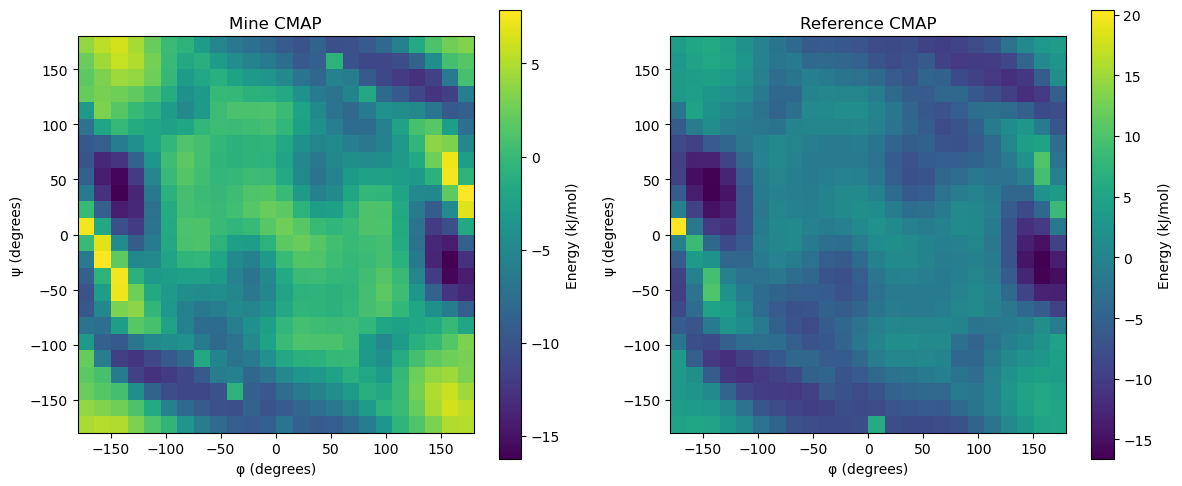

In [12]:
import numpy as np
key = ('C', 'NH1', 'CT', 'C', 'NH1')
mine_grid = mine_data[key].reshape(24, 24)
ref_grid = ref_data[key].reshape(24, 24)
angles = [f"{-180 + i*15:4d}" for i in range(24)]

import matplotlib.pyplot as plt
plt.subplots(1, 2, figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.title("Mine CMAP")
plt.imshow(mine_grid, origin='lower', extent=[-180, 180, -180, 180])
plt.xlabel("φ (degrees)")
plt.ylabel("ψ (degrees)")
plt.colorbar(label="Energy (kJ/mol)")
plt.subplot(1, 2, 2)
plt.title("Reference CMAP")
plt.imshow(ref_grid, origin='lower', extent=[-180, 180, -180, 180])
plt.xlabel("φ (degrees)")
plt.ylabel("ψ (degrees)")
plt.colorbar(label="Energy (kJ/mol)")
plt.tight_layout()
plt.show()

### Nonbonded

In [10]:
from collections import defaultdict


# =====================================================================
# NonbondedForce comparison (charges, sigma, epsilon per type/class)
# =====================================================================
print("=" * 60)
print("NonbondedForce")
print("=" * 60)

def get_nb_params(tree):
    """Extract NonbondedForce atom params, keyed by type or class."""
    nb = tree.find('.//NonbondedForce')
    if nb is None:
        return {}, {}
    
    attrs = {
        'coulomb14scale': nb.get('coulomb14scale'),
        'lj14scale': nb.get('lj14scale'),
    }
    
    params = {}
    for atom in nb.findall('Atom'):
        # Key by whichever attribute exists
        key = atom.get('class') or atom.get('type')
        sigma = float(atom.get('sigma', 0))
        eps = float(atom.get('epsilon', 0))
        charge = atom.get('charge', None)
        params[key] = {'sigma': sigma, 'epsilon': eps, 'charge': charge}
    
    return attrs, params

ref_nb_attrs, ref_nb = get_nb_params(ref_tree)
mine_nb_attrs, mine_nb = get_nb_params(mine_tree)

print(f"\nRef  attrs: {ref_nb_attrs}")
print(f"Mine attrs: {mine_nb_attrs}")

# Check UseAttributeFromResidue
for name, tree in [('ref', ref_tree), ('mine', mine_tree)]:
    uses = tree.findall('.//NonbondedForce/UseAttributeFromResidue')
    attrs = [u.get('name') for u in uses]
    print(f"{name} UseAttributeFromResidue: {attrs}")

# Compare matching classes
common = set(ref_nb) & set(mine_nb)
ref_only = set(ref_nb) - set(mine_nb)
mine_only = set(mine_nb) - set(ref_nb)

print(f"\nCommon classes: {len(common)}")
print(f"Ref only: {len(ref_only)}")
print(f"Mine only: {len(mine_only)}")

if mine_only:
    print(f"  Mine-only examples: {sorted(mine_only)[:10]}")
if ref_only:
    print(f"  Ref-only examples: {sorted(ref_only)[:10]}")

mismatches = []
for key in sorted(common):
    r, m = ref_nb[key], mine_nb[key]
    sig_diff = abs(r['sigma'] - m['sigma'])
    eps_diff = abs(r['epsilon'] - m['epsilon'])
    if sig_diff > 1e-6 or eps_diff > 1e-6:
        mismatches.append((key, sig_diff, eps_diff))

if mismatches:
    print(f"\nNonbondedForce mismatches ({len(mismatches)}):")
    for key, sd, ed in mismatches[:15]:
        print(f"  {key}: sigma_diff={sd:.8f} eps_diff={ed:.8f}")
else:
    print("\nAll common NonbondedForce params match!")

# =====================================================================
# LennardJonesForce comparison (actual LJ params per type/class)
# =====================================================================
print("\n" + "=" * 60)
print("LennardJonesForce")
print("=" * 60)

def get_lj_params(tree):
    """Extract LJ atom params and NBFix pairs."""
    lj = tree.find('.//LennardJonesForce')
    if lj is None:
        return {}, {}, {}
    
    attrs = {'lj14scale': lj.get('lj14scale')}
    
    params = {}
    for atom in lj.findall('Atom'):
        key = atom.get('class') or atom.get('type')
        sigma = float(atom.get('sigma', 0))
        eps = float(atom.get('epsilon', 0))
        params[key] = {'sigma': sigma, 'epsilon': eps}
    
    nbfix = {}
    for pair in lj.findall('NBFixPair'):
        c1 = pair.get('class1') or pair.get('type1')
        c2 = pair.get('class2') or pair.get('type2')
        key = tuple(sorted([c1, c2]))
        sigma = float(pair.get('sigma', 0))
        eps = float(pair.get('epsilon', 0))
        nbfix[key] = {'sigma': sigma, 'epsilon': eps}
    
    return attrs, params, nbfix

ref_lj_attrs, ref_lj, ref_nbfix = get_lj_params(ref_tree)
mine_lj_attrs, mine_lj, mine_nbfix = get_lj_params(mine_tree)

print(f"\nRef  attrs: {ref_lj_attrs}")
print(f"Mine attrs: {mine_lj_attrs}")

# Compare LJ atom params
common_lj = set(ref_lj) & set(mine_lj)
ref_only_lj = set(ref_lj) - set(mine_lj)
mine_only_lj = set(mine_lj) - set(ref_lj)

print(f"\nAtom params - Common: {len(common_lj)}, "
      f"Ref only: {len(ref_only_lj)}, Mine only: {len(mine_only_lj)}")

if mine_only_lj:
    print(f"  Mine-only examples: {sorted(mine_only_lj)[:10]}")

lj_mismatches = []
for key in sorted(common_lj):
    r, m = ref_lj[key], mine_lj[key]
    sig_diff = abs(r['sigma'] - m['sigma'])
    eps_diff = abs(r['epsilon'] - m['epsilon'])
    if sig_diff > 1e-6 or eps_diff > 1e-6:
        lj_mismatches.append((key, r['sigma'], m['sigma'],
                              r['epsilon'], m['epsilon']))

if lj_mismatches:
    print(f"\nLJ param mismatches ({len(lj_mismatches)}):")
    print(f"  {'Class':<12s} {'ref_σ':>12s} {'mine_σ':>12s} "
          f"{'ref_ε':>12s} {'mine_ε':>12s}")
    for key, rs, ms, re, me in lj_mismatches[:20]:
        print(f"  {key:<12s} {rs:12.8f} {ms:12.8f} {re:12.8f} {me:12.8f}")
else:
    print("\nAll common LJ params match!")

# Compare NBFix pairs
common_nbfix = set(ref_nbfix) & set(mine_nbfix)
ref_only_nbfix = set(ref_nbfix) - set(mine_nbfix)
mine_only_nbfix = set(mine_nbfix) - set(ref_nbfix)

print(f"\nNBFix pairs - Common: {len(common_nbfix)}, "
      f"Ref only: {len(ref_only_nbfix)}, Mine only: {len(mine_only_nbfix)}")

nbfix_mismatches = []
for key in sorted(common_nbfix):
    r, m = ref_nbfix[key], mine_nbfix[key]
    sig_diff = abs(r['sigma'] - m['sigma'])
    eps_diff = abs(r['epsilon'] - m['epsilon'])
    if sig_diff > 1e-6 or eps_diff > 1e-6:
        nbfix_mismatches.append((key, r['sigma'], m['sigma'],
                                 r['epsilon'], m['epsilon']))

if nbfix_mismatches:
    print(f"\nNBFix mismatches ({len(nbfix_mismatches)}):")
    print(f"  {'Pair':<25s} {'ref_σ':>12s} {'mine_σ':>12s} "
          f"{'ref_ε':>12s} {'mine_ε':>12s}")
    for key, rs, ms, re, me in nbfix_mismatches[:20]:
        pair_str = f"{key[0]}-{key[1]}"
        print(f"  {pair_str:<25s} {rs:12.8f} {ms:12.8f} "
              f"{re:12.8f} {me:12.8f}")
else:
    print("\nAll common NBFix params match!")

if ref_only_nbfix:
    print(f"\n  Ref-only NBFix examples: {sorted(ref_only_nbfix)[:5]}")
if mine_only_nbfix:
    print(f"  Mine-only NBFix examples: {sorted(mine_only_nbfix)[:5]}")

NonbondedForce

Ref  attrs: {'coulomb14scale': '1.0', 'lj14scale': '1.0'}
Mine attrs: {'coulomb14scale': '1.0', 'lj14scale': '1.0'}
ref UseAttributeFromResidue: ['charge']
mine UseAttributeFromResidue: ['charge']

Common classes: 392
Ref only: 85
Mine only: 58
  Mine-only examples: ['AG', 'AL', 'ALSI', 'AU', 'BAR', 'CAD', 'CAL', 'CC30A', 'CC31A', 'CC325A']
  Ref-only examples: ['CAP', 'CF1', 'CF2', 'CF3', 'CLAL', 'CLG01', 'CLG02', 'CLG03', 'CLG04', 'CLG05']

All common NonbondedForce params match!

LennardJonesForce

Ref  attrs: {'lj14scale': '1.0'}
Mine attrs: {'lj14scale': '1.0'}

Atom params - Common: 392, Ref only: 85, Mine only: 58
  Mine-only examples: ['AG', 'AL', 'ALSI', 'AU', 'BAR', 'CAD', 'CAL', 'CC30A', 'CC31A', 'CC325A']

LJ param mismatches (160):
  Class               ref_σ       mine_σ        ref_ε       mine_ε
  BG201          0.45435835   0.45435835   0.15899200   0.15899000
  CAI            0.35457769   0.35457769   0.30543200   0.30543000
  CC1A           0.37239566 

### Impropers
So far, I've corrected/changed the Script that is written at the end of the XML, and it seems to have similar setups/values as the true charmm one. We are still getting different values for the energies though.

In [16]:
from openmm import CustomTorsionForce
import math

ctf = [f for f in system.getForces() if isinstance(f, CustomTorsionForce)][0]
atoms_list = list(modeller.topology.atoms())

print(f"OpenMM: {ctf.getNumTorsions()} impropers")
print(f"GROMACS: 12 impropers")
print(f"Energy expression: {ctf.getEnergyFunction()}\n")
state = simulation.context.getState(getEnergy=True, groups={ctf.getForceGroup()})
ctf_energy = state.getPotentialEnergy()
# Print all impropers with their current angles
positions = simulation.context.getState(getPositions=True).getPositions(asNumpy=True)

def calc_dihedral(p1, p2, p3, p4):
    """Calculate dihedral angle in radians."""
    import numpy as np
    b1 = p2 - p1
    b2 = p3 - p2
    b3 = p4 - p3
    n1 = np.cross(b1, b2)
    n2 = np.cross(b2, b3)
    n1 /= np.linalg.norm(n1)
    n2 /= np.linalg.norm(n2)
    m1 = np.cross(n1, b2 / np.linalg.norm(b2))
    x = np.dot(n1, n2)
    y = np.dot(m1, n2)
    return math.atan2(y, x)

import numpy as np
pos = positions.value_in_unit(positions.unit)

print(f"{'Atoms':45s} {'k':>10s} {'theta0':>8s} {'angle':>8s} {'energy':>10s}")
print("-" * 85)
total_E = 0
for i in range(ctf.getNumTorsions()):
    idx1, idx2, idx3, idx4, params = ctf.getTorsionParameters(i)
    k, theta0 = params
    names = [f"{atoms_list[j].residue.name}:{atoms_list[j].name}({atoms_list[j].id})" 
             for j in (idx1, idx2, idx3, idx4)]
    
    angle = calc_dihedral(pos[idx1], pos[idx2], pos[idx3], pos[idx4])
    dtheta = abs(angle - theta0)
    dtheta = min(dtheta, 2*math.pi - dtheta)
    energy = 0.5 * k * dtheta**2
    total_E += energy
    
    print(f"{' '.join(names):45s} {k:10.2f} {theta0:8.4f} "
          f"{math.degrees(angle):8.2f} {energy:10.4f}")

print(f"\nSum of improper energies: {total_E:.4f} kJ/mol")
print(f"OpenMM reports:          {ctf_energy} kJ/mol")

OpenMM: 11 impropers
GROMACS: 12 impropers
Energy expression: k*min(dtheta, 2*pi - dtheta)^2; dtheta = abs(theta - theta0); pi = 3.141592653589793

Atoms                                                  k   theta0    angle     energy
-------------------------------------------------------------------------------------
ACE:C(5) ACE:CH3(1) ALA:N(7) ACE:O(6)             502.08   0.0000    -0.28     0.0058
ALA:N(7) ACE:C(5) ALA:CA(9) ALA:H(8)               83.68   0.0000     0.42     0.0023
ALA:C(15) ALA:CA(9) ALA:N(17) ALA:O(16)           502.08   0.0000     0.20     0.0029
ALA:N(17) ALA:C(15) ALA:CA(19) ALA:H(18)           83.68   0.0000    -0.13     0.0002
ALA:C(25) ALA:CA(19) ALA:N(27) ALA:O(26)          502.08   0.0000    -0.33     0.0083
ALA:N(27) ALA:C(25) ALA:CA(29) ALA:H(28)           83.68   0.0000     0.55     0.0038
ALA:C(35) ALA:CA(29) ALA:N(37) ALA:O(36)          502.08   0.0000     0.26     0.0050
ALA:N(37) ALA:C(35) ALA:CA(39) ALA:H(38)           83.68   0.0000    -0.12    

In [19]:

# Check what the Script sees for the NME residue
nme_res = [r for r in modeller.topology.residues() if r.name == 'NME'][0]
prev_res = list(modeller.topology.residues())[nme_res.index - 1]

print(f"\nNME atoms: {[a.name for a in nme_res.atoms()]}")
print(f"Prev res ({prev_res.name}) atoms: {[a.name for a in prev_res.atoms()]}")

# Check if inter-residue bond exists
nme_atoms = {a.name: a for a in nme_res.atoms()}
prev_atoms = {a.name: a for a in prev_res.atoms()}

print("\nInter-residue bonds involving NME:")
for b in modeller.topology.bonds():
    a1, a2 = b[0], b[1]
    if (a1.residue == nme_res and a2.residue == prev_res) or \
       (a2.residue == nme_res and a1.residue == prev_res):
        print(f"  {a1.residue.name}:{a1.name} -- {a2.residue.name}:{a2.name}")


NME atoms: ['N', 'H', 'C', 'H1', 'H2', 'H3']
Prev res (ALA) atoms: ['N', 'H', 'CA', 'HA', 'CB', 'HB1', 'HB2', 'HB3', 'C', 'O']

Inter-residue bonds involving NME:
  ALA:C -- NME:N


## Running sims for testing XML

In [ ]:
import parmed as pmd
from parmed import load_file
from parmed.openmm.reporters import NetCDFReporter
from parmed import unit as u
from openmm.app import *
from openmm import *
from openmm.unit import *
from sys import stdout

import os
os.environ['GMXLIB'] = "/scratch/midway3/gruschka/toid_explore/forcefields/"
randompdb = "/scratch/midway3/gruschka/metal-toids/structure_maker/test_ZZZZZ.pdb"

box_size = 5.0
# Tell openmm where to look for bonds
Topology.loadBondDefinitions("spce_mosic.xml")
pdb = PDBFile(randompdb)
forcefield = ForceField('mosic.xml', 'spce_mosic.xml')

modeller = Modeller(pdb.topology, pdb.positions)
residue_map = {res: res.name for res in pdb.topology.residues()}
# modeller.addSolvent(forcefield, 
#                     boxSize=Vec3(box_size, box_size, box_size)*nanometers,
#                     model='spce',
#                     residueTemplates=residue_map,
#                     )
# solvent_names = {'HOH', 'WAT', 'SOL', 'NA', 'CL', 'Na+', 'Cl-'}
# solute_indices = [
#     atom.index for atom in modeller.topology.atoms()
#     if atom.residue.name not in solvent_names
# ]

system = forcefield.createSystem(modeller.topology,# nonbondedMethod=PME,
        #nonbondedCutoff=1*nanometer, constraints=HBonds, 
        residueTemplates=residue_map)
integrator = LangevinMiddleIntegrator(300*kelvin, 1/picosecond, 0.002*picoseconds)

for i, f in enumerate(system.getForces()):
    f.setForceGroup(i)
simulation = Simulation(modeller.topology, system, integrator)
simulation.context.setPositions(modeller.positions)
simulation.minimizeEnergy()
# Write the trajectory to a file called "output.pdb"
simulation.reporters.append(PDBReporter('output.pdb', 100,atomSubset=solute_indices))

# Report infomation to the screen as the simulation runs
simulation.reporters.append(StateDataReporter(stdout, 100, step=True,
        potentialEnergy=True, temperature=True))

#Run the simulation for 1000 timsteps
print("Running simulation...")
simulation.step(1000)

ValueError: No harmonic improper params for classes ['ACEp-CLP', 'ACEp-CAY', 'NSPE-NL', 'ACEp-OL'] in residue ACEp (index 0)

In [ ]:
for i, f in enumerate(system.getForces()):
    state = simulation.context.getState(energy=True, groups={i})
    print(f.getName(), state.getPotentialEnergy())

nonbonded = [f for f in system.getForces() if isinstance(f, NonbondedForce)][0]
atoms = list(modeller.topology.atoms())
template = forcefield._templates['ACEp']
for a in template.atoms:
    print(a.name, vars(a))

In [ ]:
custom_torsion = [f for f in system.getForces() if isinstance(f, CustomTorsionForce)][0]
print(f"Number of torsions: {custom_torsion.getNumTorsions()}")
for i in range(min(custom_torsion.getNumTorsions(), 10)):
    print(custom_torsion.getTorsionParameters(i))

## Test and compare a Peptide - charmm vs gromacs derived ff

In [ ]:
# Initialize
import parmed as pmd
from parmed import load_file
from parmed.openmm.reporters import NetCDFReporter
from parmed import unit as u
from openmm.app import *
from openmm import *
from openmm.unit import *
from sys import stdout

import os

pdb_loc = "/scratch/midway3/gruschka/metal-toids/peptide.pdb"
box_size = 5.0
# Tell openmm where to look for bonds
# Topology.loadBondDefinitions("spce_mosic.xml")
pdb = PDBFile(pdb_loc)
forcefield = ForceField('spce_mosic.xml')
modeller = Modeller(pdb.topology, pdb.positions)
residue_map = {res: res.name for res in modeller.topology.residues()}

modeller.addSolvent(forcefield, 
                    boxSize=Vec3(box_size, box_size, box_size)*nanometers,
                    model='spce', residueTemplates=residue_map
                    )
solvent_names = {'HOH', 'WAT', 'SOL', 'NA', 'CL', 'Na+', 'Cl-'}
solute_indices = [
    atom.index for atom in modeller.topology.atoms()
    if atom.residue.name not in solvent_names
]
residue_map = {res: res.name for res in modeller.topology.residues() if res.name != "HOH"} # Have to remake to ensure poitning correctly
system = forcefield.createSystem(modeller.topology, nonbondedMethod=PME,
        nonbondedCutoff=1*nanometer, constraints=HBonds,
        residueTemplates=residue_map)
integrator = LangevinMiddleIntegrator(300*kelvin, 1/picosecond, 0.002*picoseconds)

for i, f in enumerate(system.getForces()):
    f.setForceGroup(i)
simulation = Simulation(modeller.topology, system, integrator)
simulation.context.setPositions(modeller.positions)
simulation.minimizeEnergy()
# Write the trajectory to a file called "output.pdb"
simulation.reporters.append(PDBReporter('output.pdb', 100,atomSubset=solute_indices))

# Report infomation to the screen as the simulation runs
simulation.reporters.append(StateDataReporter(stdout, 100, step=True,
        potentialEnergy=True, temperature=True))

#Run the simulation for 1000 timsteps
print("Running simulation...")
simulation.step(1000)


Exception: User-supplied template ACE does not match the residue 0 (ACE)

In [ ]:
for i, f in enumerate(system.getForces()):
    state = simulation.context.getState(energy=True, groups={i})
    print(f.getName(), state.getPotentialEnergy())

HarmonicBondForce 77.30715286043994 kJ/mol
PeriodicTorsionForce 58.432483615406696 kJ/mol
NonbondedForce -199475.01162152088 kJ/mol
LennardJones 20733.737017057847 kJ/mol
CMMotionRemover 0.0 kJ/mol
HarmonicAngleForce 125.22983005344112 kJ/mol
LennardJones14 86.20130817650126 kJ/mol
CustomTorsionForce 7.837943091123572 kJ/mol


In [3]:
# Fix pdb for ACE/NME with CHARMM-GUI, use the output step1_pdbreader.pdb and .psf files to work with openmm

In [ ]:
# Initialize
import parmed as pmd
from parmed import load_file
from parmed.openmm.reporters import NetCDFReporter
from parmed import unit as u
from openmm.app import *
from openmm import *
from openmm.unit import *
from sys import stdout

import os

pdb_loc = "step1_pdbreader.pdb"
psf_loc = "ACE_GAGAGA_NME.psf"
psf = CharmmPsfFile(psf_loc)
box_size = 5.0
# Tell openmm where to look for bonds
# Topology.loadBondDefinitions()
pdb = PDBFile(pdb_loc)
# print(residue_map)
forcefield = ForceField('charmm36_2024.xml', 'charmm36_2024/spce.xml')
modeller = Modeller(psf.topology, pdb.positions)
residue_map = {res: res.name for res in modeller.topology.residues()}

modeller.addSolvent(forcefield, 
                    boxSize=Vec3(box_size, box_size, box_size)*nanometers,
                    model='spce'#, residueTemplates=residue_map
                    )
solvent_names = {'HOH', 'WAT', 'SOL', 'NA', 'CL', 'Na+', 'Cl-'}
solute_indices = [
    atom.index for atom in modeller.topology.atoms()
    if atom.residue.name not in solvent_names
]
residue_map = {res: res.name for res in modeller.topology.residues() if res.name != "HOH"} # Have to remake to ensure poitning correctly
system = forcefield.createSystem(modeller.topology, nonbondedMethod=PME,
        nonbondedCutoff=1*nanometer, constraints=HBonds)
integrator = LangevinMiddleIntegrator(300*kelvin, 1/picosecond, 0.002*picoseconds)

for i, f in enumerate(system.getForces()):
    f.setForceGroup(i)
simulation = Simulation(modeller.topology, system, integrator)
simulation.context.setPositions(modeller.positions)
simulation.minimizeEnergy()
# Write the trajectory to a file called "output.pdb"
simulation.reporters.append(PDBReporter('output_true.pdb', 100,atomSubset=solute_indices))

# Report infomation to the screen as the simulation runs
simulation.reporters.append(StateDataReporter(stdout, 100, step=True,
        potentialEnergy=True, temperature=True))

#Run the simulation for 1000 timsteps
print("Running simulation...")
simulation.step(1000)


/scratch/midway3/gruschka/metal-toid/lib/python3.10/site-packages/openmm/app/internal/pdbstructure.py:441: UserWarning: WARNING: two consecutive residues with same number (ATOM      6  OY  GLY P   1      41.657  30.132  27.135  1.00  0.00      PROA    , ATOM      5  CY  ACE P   1      41.507  31.188  27.747  1.00  0.00      PROA    )
  warnings.warn("WARNING: two consecutive residues with same number (%s, %s)" % (atom, self._current_residue.atoms[-1]))


In [ ]:
for i, f in enumerate(system.getForces()):
    state = simulation.context.getState(energy=True, groups={i})
    print(f.getName(), state.getPotentialEnergy())

HarmonicBondForce 64.58803203220002 kJ/mol
PeriodicTorsionForce 61.33950426097618 kJ/mol
CMAPTorsionForce -30.21311902339093 kJ/mol
NonbondedForce -238940.76141375597 kJ/mol
LennardJones 39632.19446080153 kJ/mol
CMMotionRemover 0.0 kJ/mol
HarmonicAngleForce 115.93171966871392 kJ/mol
LennardJones14 11.301008529363866 kJ/mol
CustomTorsionForce 13.38516441044401 kJ/mol


### Single Point Energy Calc

#### OpenMM Results

In [4]:
# Single point comparison to gromacs
# Initialize
import parmed as pmd
from parmed import load_file
from parmed.openmm.reporters import NetCDFReporter
from parmed import unit as u
from openmm.app import *
from openmm import *
from openmm.unit import *
from sys import stdout

import os
os.environ['GMXLIB'] = "/scratch/midway3/gruschka/toid_explore/forcefields/"
gro = GromacsGroFile('./translation_tests/conf_box.gro')
top = GromacsTopFile('./translation_tests/topol.top', includeDir=os.environ['GMXLIB'],periodicBoxVectors=gro.getPeriodicBoxVectors()).topology

box_size = 5.0
# Tell openmm where to look for bonds
# Topology.loadBondDefinitions()
# pdb = PDBFile(pdb_loc)

modeller = Modeller(top, gro.positions)
residue_map = {res: res.name for res in modeller.topology.residues() }
forcefield = ForceField('mosic.xml', 'charmm36_2024/spce.xml')
system = forcefield.createSystem(modeller.topology, nonbondedMethod=PME,
        nonbondedCutoff=1*nanometer, constraints=None,
        residueTemplates=residue_map)  # not HBonds

# integrator = VerletIntegrator(0.001 * picoseconds)
integrator = LangevinMiddleIntegrator(300*kelvin, 1/picosecond, 0.002*picoseconds)

for i, f in enumerate(system.getForces()):
    f.setForceGroup(i)
simulation = Simulation(modeller.topology, system, integrator)
simulation.context.setPositions(gro.positions)

# Get total energy
state = simulation.context.getState(getEnergy=True)
print(f"Total: {state.getPotentialEnergy()}")

# Per-force breakdown
for i, force in enumerate(system.getForces()):
    state = simulation.context.getState(getEnergy=True, groups={i})
    print(f"  {force.getName()}: {state.getPotentialEnergy()}")

Total: 26764.108959571437 kJ/mol
  HarmonicBondForce: 362.4729788485788 kJ/mol
  PeriodicTorsionForce: 201.3951872704759 kJ/mol
  CMAPTorsionForce: -36.72894569301675 kJ/mol
  NonbondedForce: 154.2348910631821 kJ/mol
  LennardJones: 24068.721982493676 kJ/mol
  CMMotionRemover: 0.0 kJ/mol
  HarmonicAngleForce: 462.95177516692195 kJ/mol
  LennardJones14: 47.51624878246757 kJ/mol
  CustomTorsionForce: 1503.544841639152 kJ/mol


#### GROMACS energy results

In [40]:
import panedr

df = panedr.edr_to_df('./translation_tests/ener.edr')
print(df.columns.tolist())  # see all available energy terms
print(df.iloc[0])           # first (only) frame

['Time', 'Bond', 'U-B', 'Proper Dih.', 'Improper Dih.', 'CMAP Dih.', 'LJ-14', 'Coulomb-14', 'LJ (SR)', 'Coulomb (SR)', 'Coul. recip.', 'Potential']
Time                 0.000000
Bond               338.060852
U-B                487.362183
Proper Dih.        201.394485
Improper Dih.     1503.245117
CMAP Dih.          -29.433889
LJ-14               47.516212
Coulomb-14        1501.430786
LJ (SR)          24069.919922
Coulomb (SR)     -1398.339966
Coul. recip.        51.109669
Potential        26772.265625
Name: 0.0, dtype: float64


In [41]:
for i, force in enumerate(system.getForces()):
    name = force.__class__.__name__
    # Print force details to identify what each one is
    if hasattr(force, 'getNumBonds'):
        print(f"{i}: {name} - {force.getNumBonds()} bonds")
    elif hasattr(force, 'getNumTorsions'):
        print(f"{i}: {name} - {force.getNumTorsions()} torsions")
    elif hasattr(force, 'getEnergyFunction'):
        print(f"{i}: {name} - energy: {force.getEnergyFunction()}")
    elif hasattr(force, 'getNumParticles'):
        print(f"{i}: {name} - {force.getNumParticles()} particles")
    else:
        print(f"{i}: {name}")

0: HarmonicBondForce - 100 bonds
1: PeriodicTorsionForce - 50 torsions
2: CMAPTorsionForce - 5 torsions
3: NonbondedForce - 62 particles
4: CustomNonbondedForce - energy: acoef(type1, type2)/r^12 - bcoef(type1, type2)/r^6;
5: CMMotionRemover
6: HarmonicAngleForce
7: CustomBondForce - 141 bonds
8: CustomTorsionForce - 5 torsions


In [43]:
# Check what's in the CustomTorsionForce
ctf = [f for f in system.getForces() if isinstance(f, CustomTorsionForce)][0]
print(f"Energy expression: {ctf.getEnergyFunction()}")
print(f"Num torsions: {ctf.getNumTorsions()}")
atoms_list = list(modeller.topology.atoms())
for i in range(ctf.getNumTorsions()):
    idx1, idx2, idx3, idx4, params = ctf.getTorsionParameters(i)
    k, theta0 = params
    names = [f"{atoms_list[j].residue.name}-{atoms_list[j].name}" 
             for j in (idx1, idx2, idx3, idx4)]
    print(f"  {' '.join(names):40s}  k={k:.4f}  theta0={theta0:.4f}")

Energy expression: 0.5*k*min(dtheta, 2*3.141592653589793 - dtheta)^2; dtheta = abs(theta - theta0)
Num torsions: 5
  ALA-C ALA-CA ALA-N ALA-O                  k=1004.1600  theta0=0.0000
  ALA-C ALA-CA ALA-N ALA-O                  k=1004.1600  theta0=0.0000
  ALA-C ALA-CA ALA-N ALA-O                  k=1004.1600  theta0=0.0000
  ALA-C ALA-CA ALA-N ALA-O                  k=1004.1600  theta0=0.0000
  ALA-C ALA-CA NME-N ALA-O                  k=1004.1600  theta0=0.0000


In [44]:
# Are UB terms accidentally in HarmonicBondForce too?
hbf = [f for f in system.getForces() if isinstance(f, HarmonicBondForce)][0]
print(f"HarmonicBondForce: {hbf.getNumBonds()} bonds")
for i in range(min(hbf.getNumBonds(), 5)):
    p1, p2, length, k = hbf.getBondParameters(i)
    names = f"{atoms_list[p1].residue.name}-{atoms_list[p1].name} -- {atoms_list[p2].residue.name}-{atoms_list[p2].name}"
    print(f"  {names:30s} length={length} k={k}")

cbf = [f for f in system.getForces() if isinstance(f, CustomBondForce)][0]
print(f"\nCustomBondForce: {cbf.getNumBonds()} bonds")
print(f"Energy expression: {cbf.getEnergyFunction()}")

HarmonicBondForce: 100 bonds
  ACE-CH3 -- ACE-H1              length=0.1111 nm k=269449.6 kJ/(nm**2 mol)
  ACE-CH3 -- ACE-H2              length=0.1111 nm k=269449.6 kJ/(nm**2 mol)
  ACE-CH3 -- ACE-H3              length=0.1111 nm k=269449.6 kJ/(nm**2 mol)
  ACE-CH3 -- ACE-C               length=0.149 nm k=209200.0 kJ/(nm**2 mol)
  ACE-C -- ACE-O                 length=0.123 nm k=518816.0 kJ/(nm**2 mol)

CustomBondForce: 141 bonds
Energy expression: 4*epsilon*((sigma/r)^12-(sigma/r)^6)


In [45]:
hbf = [f for f in system.getForces() if isinstance(f, HarmonicBondForce)][0]
real_bonds = 0
ub_bonds = 0
for i in range(hbf.getNumBonds()):
    p1, p2, length, k = hbf.getBondParameters(i)
    length_nm = length.value_in_unit(nanometer)
    if length_nm > 0.2:
        ub_bonds += 1
        if ub_bonds <= 3:
            a1, a2 = atoms_list[p1], atoms_list[p2]
            print(f"  UB: {a1.residue.name}-{a1.name} -- {a2.residue.name}-{a2.name} "
                  f"length={length_nm:.4f} k={k}")
    else:
        real_bonds += 1
print(f"\nReal bonds: {real_bonds}, UB bonds: {ub_bonds}")

  UB: ACE-H1 -- ACE-C length=0.2163 k=25104.0 kJ/(nm**2 mol)
  UB: ACE-H2 -- ACE-C length=0.2163 k=25104.0 kJ/(nm**2 mol)
  UB: ACE-H3 -- ACE-C length=0.2163 k=25104.0 kJ/(nm**2 mol)

Real bonds: 82, UB bonds: 18


# System Building/setup (pre-simulation)

### Developing Load System, starting from Gromacs Files

In [3]:
from openmm.app import *
from openmm import *
from openmm.unit import *
from sys import stdout
import os

os.environ['GMXLIB'] = "/scratch/midway3/gruschka/toid_explore/forcefields/"


In [4]:
gro = GromacsGroFile('./translation_tests/conf_box.gro')
top = GromacsTopFile('./translation_tests/topol.top', includeDir=os.environ['GMXLIB'],periodicBoxVectors=gro.getPeriodicBoxVectors()).topology

modeller = Modeller(top, gro.positions)

In [5]:
with open('openmm_viable_AAAAA.pdb', 'w', encoding='utf-8') as f:
    # 2. Pass the modeller's topology and positions to PDBFile.writeFile
    PDBFile.writeFile(modeller.getTopology(), modeller.getPositions(), f)

In [6]:
def add_bonds_from_forcefield(topology, forcefield):
    """Add missing bonds to a topology using force field templates."""
    
    # Track existing bonds to avoid duplicates
    existing = set()
    for bond in topology.bonds():
        existing.add((bond[0].index, bond[1].index))
        existing.add((bond[1].index, bond[0].index))
    
    def safe_add(a1, a2):
        if (a1.index, a2.index) not in existing:
            topology.addBond(a1, a2)
            existing.add((a1.index, a2.index))
            existing.add((a2.index, a1.index))
    
    # Intra-residue bonds from templates
    for res in topology.residues():
        if res.name not in forcefield._templates:
            continue
        template = forcefield._templates[res.name]
        atom_map = {a.name: a for a in res.atoms()}
        template_atoms = list(template.atoms)
        for bond in template.bonds:
            a1_name = template_atoms[bond[0]].name
            a2_name = template_atoms[bond[1]].name
            if a1_name in atom_map and a2_name in atom_map:
                safe_add(atom_map[a1_name], atom_map[a2_name])

old_pdb = PDBFile('openmm_viable_AAAAA.pdb')
new_pdb = PDBFile('openmm_viable_AAAAA.pdb')
ff = ForceField('spce_mosic.xml')
add_bonds_from_forcefield(new_pdb.topology, ff)

In [7]:
Topology.loadBondDefinitions("spce_mosic.xml")
forcefield = ForceField('spce_mosic.xml')
modeller = Modeller(old_pdb.topology, old_pdb.positions)
residue_map = {res: res.name for res in modeller.topology.residues()}
modeller.addSolvent(forcefield, 
                    boxSize=Vec3(5.0, 5.0, 5.0)*nanometers,
                    model='spce',
                    residueTemplates=residue_map)
residue_map = {res: res.name for res in modeller.topology.residues() if res.name != "HOH"}
system = forcefield.createSystem(modeller.topology, nonbondedMethod=PME,
        nonbondedCutoff=1*nanometer, constraints=HBonds,
        residueTemplates=residue_map)

In [8]:
# Check template bond structure
for resname in ['ACE', 'ALA', 'NME','CTM']:
    if resname in forcefield._templates:
        t = forcefield._templates[resname]
        template_atoms = list(t.atoms)
        print(f"\n{resname}: {len(list(t.bonds))} template bonds")
        for bond in t.bonds:
            print(f"  bond type: {type(bond)}, value: {bond}")
            # Try different access patterns
            try:
                print(f"    [0],[1]: {bond[0]}, {bond[1]}")
            except:
                pass
            try:
                print(f"    .atom1,.atom2: {bond.atom1}, {bond.atom2}")
            except:
                pass
            break  # just check one


ACE: 5 template bonds
  bond type: <class 'tuple'>, value: (4, 0)
    [0],[1]: 4, 0

ALA: 9 template bonds
  bond type: <class 'tuple'>, value: (4, 2)
    [0],[1]: 4, 2

NME: 5 template bonds
  bond type: <class 'tuple'>, value: (0, 1)
    [0],[1]: 0, 1

CTM: 20 template bonds
  bond type: <class 'tuple'>, value: (0, 1)
    [0],[1]: 0, 1


In [ ]:
# Returns a set of bond tuples (residue_index1, atom_name1, residue_index2, atom_name2) for comparisons
def bond_set(topology):
    return {
        (b[0].residue.index, b[0].name, b[1].residue.index, b[1].name)
        for b in topology.bonds()
    }

new_bonds = bond_set(new_pdb.topology)
old_bonds = bond_set(old_pdb.topology)

in_old_only = old_bonds - new_bonds
in_new_only = new_bonds - old_bonds

print(f"Old: {len(old_bonds)}, New: {len(new_bonds)}")
print(f"\nIn old only ({len(in_old_only)}):")
for ri1, a1, ri2, a2 in sorted(in_old_only):
    print(f"  res{ri1}:{a1} -- res{ri2}:{a2}")
print(f"\nIn new only ({len(in_new_only)}):")
for ri1, a1, ri2, a2 in sorted(in_new_only):
    print(f"  res{ri1}:{a1} -- res{ri2}:{a2}")

Old: 61, New: 61

In old only (0):

In new only (0):


### Developing Load System from structure maker

In [5]:
from openmm.app import *
from openmm import *
from openmm.unit import *
from sys import stdout
import os

os.environ['GMXLIB'] = "/scratch/midway3/gruschka/toid_explore/forcefields/"

In [6]:
forcefield = ForceField('spce_mosic.xml')
for resname in ['ACE', 'ALA', 'NME']:
    t = forcefield._templates[resname]
    ta = list(t.atoms)
    print(f"\n{resname}:")
    print(f"  externalBonds: {list(t.externalBonds)}")
    print(f"  all bonds: {list(t.bonds)}")
    print(f"  atoms: {[a.name for a in ta]}")


ACE:
  externalBonds: [4]
  all bonds: [(4, 0), (0, 1), (0, 2), (0, 3), (5, 4)]
  atoms: ['CAY', 'HY1', 'HY2', 'HY3', 'C', 'O']

ALA:
  externalBonds: [8, 0]
  all bonds: [(4, 2), (0, 1), (0, 2), (8, 2), (2, 3), (4, 5), (4, 6), (4, 7), (9, 8)]
  atoms: ['N', 'HN', 'CA', 'HA', 'CB', 'HB1', 'HB2', 'HB3', 'C', 'O']

NME:
  externalBonds: [0]
  all bonds: [(0, 1), (0, 2), (2, 3), (2, 4), (2, 5)]
  atoms: ['NT', 'HNT', 'CAT', 'HT1', 'HT2', 'HT3']


In [3]:
def add_bonds_from_forcefield(topology, forcefield):
    """Add missing bonds to a topology using force field templates."""
    
    existing = set()
    for bond in topology.bonds():
        existing.add((bond[0].index, bond[1].index))
        existing.add((bond[1].index, bond[0].index))
    
    def safe_add(a1, a2):
        if (a1.index, a2.index) not in existing:
            topology.addBond(a1, a2)
            existing.add((a1.index, a2.index))
            existing.add((a2.index, a1.index))
    
    for res in topology.residues():
        if res.name not in forcefield._templates:
            continue
        template = forcefield._templates[res.name]
        atom_map = {a.name: a for a in res.atoms()}
        template_atoms = list(template.atoms)
        n_atoms = len(template_atoms)
        
        # Skip bonds involving external atom indices
        external_indices = set(template.externalBonds)
        
        for bond in template.bonds:
            # Skip if either index is out of range
            if bond[0] >= n_atoms or bond[1] >= n_atoms:
                continue
            # Skip if an bond is an external bond (i.e., connects to another residue)
            # if bond[0] in external_indices or bond[1] in external_indices:
            #     continue
            a1_name = template_atoms[bond[0]].name
            a2_name = template_atoms[bond[1]].name
            if a1_name in atom_map and a2_name in atom_map:
                safe_add(atom_map[a1_name], atom_map[a2_name])

In [7]:
# Load the new pdb 
pdb = PDBFile('./structure_maker/all_res.pdb')
Topology.loadBondDefinitions("spce_mosic.xml")
forcefield = ForceField('spce_mosic.xml')
add_bonds_from_forcefield(pdb.topology, forcefield)
modeller = Modeller(pdb.topology, pdb.positions)
residue_map = {res: res.name for res in modeller.topology.residues()}
print(f"Residue map: {residue_map.keys()}")
modeller.addSolvent(forcefield, 
                    boxSize=Vec3(5.0, 5.0, 5.0)*nanometers,
                    model='spce',
                    residueTemplates=residue_map)
residue_map = {res: res.name for res in modeller.topology.residues() if res.name not in ["HOH","CL"]}
system = forcefield.createSystem(modeller.topology, nonbondedMethod=PME,
        nonbondedCutoff=1*nanometer, constraints=HBonds,
        residueTemplates=residue_map)

Residue map: dict_keys([<Residue 0 (ACEp) of chain 0>, <Residue 1 (ALAp) of chain 0>, <Residue 2 (ARGp) of chain 0>, <Residue 3 (ASNp) of chain 0>, <Residue 4 (ASPd) of chain 0>, <Residue 5 (CYSd) of chain 0>, <Residue 6 (GLUd) of chain 0>, <Residue 7 (GLNp) of chain 0>, <Residue 8 (GLYp) of chain 0>, <Residue 9 (HSDp) of chain 0>, <Residue 10 (HSEp) of chain 0>, <Residue 11 (HSPp) of chain 0>, <Residue 12 (ILEp) of chain 0>, <Residue 13 (LEUp) of chain 0>, <Residue 14 (LYSp) of chain 0>, <Residue 15 (METd) of chain 0>, <Residue 16 (PHEp) of chain 0>, <Residue 17 (PROd) of chain 0>, <Residue 18 (SERp) of chain 0>, <Residue 19 (THRp) of chain 0>, <Residue 20 (TRPp) of chain 0>, <Residue 21 (TYRp) of chain 0>, <Residue 22 (VALp) of chain 0>, <Residue 23 (NTBp) of chain 0>, <Residue 24 (NPHp) of chain 0>, <Residue 25 (BTM) of chain 0>, <Residue 26 (BTE) of chain 0>, <Residue 27 (CTM) of chain 0>, <Residue 28 (CTE) of chain 0>, <Residue 29 (FTM) of chain 0>, <Residue 30 (FTE) of chain 0>, 

### Individual Residue Debugging
Needed to do some work to get the structure builder to properly format the pdb, as it was improperly reading atomtypes into mdtraj/writing them to the pdb (CLL -> C not Cl, same with BRL).
In testing all residues, I'm finding other errors with: CYSd,

In [10]:
import numpy as np
# Returns a set of bond tuples (residue_index1, atom_name1, residue_index2, atom_name2) for comparisons
def bond_set(topology):
    return [[int(b[0].residue.index), int(b[0].index), 
             int(b[1].residue.index), int(b[1].index)] 
            for b in topology.bonds()], [[a.name,a.residue.index] for a in topology.atoms()]

res_num = 8 # Which residue to check


bonds, atoms = bond_set(pdb.topology)
pdb_set = np.array(bonds, dtype=np.int32)
ctm_bonds = pdb_set[np.where((pdb_set[:,0]==res_num) | (pdb_set[:,2]==res_num))]

# Convert atoms to array for easy indexing
# atoms[i] = [name, residue_index] for atom i
atoms_arr = np.array(atoms, dtype=object)

# For each bond in ctm_bonds, columns 1 and 3 are atom indices
# Look up name and residue for each participating atom
for bond in ctm_bonds:
    ri1, ai1, ri2, ai2 = bond
    name1, res1 = atoms_arr[ai1]
    name2, res2 = atoms_arr[ai2]
    print(f"Res {res1}:{name1} -- Res {res2}:{name2}")

Res 7:CLP -- Res 8:NL
Res 8:CLP -- Res 9:NL
Res 8:NL -- Res 8:CA
Res 8:CLP -- Res 8:CA
Res 8:CA -- Res 8:HA1
Res 8:CA -- Res 8:HA2
Res 8:OL -- Res 8:CLP


In [14]:
# Build a name lookup from relative index within CTM template
res_name = list(pdb.topology.residues())[res_num].name
ctm_template = forcefield._templates[res_name]
template_atom_names = [a.name for a in ctm_template.atoms]

# Convert template bonds from relative indices -> name pairs
ff_bonds = set(
    frozenset((template_atom_names[i], template_atom_names[j]))
    for i, j in ctm_template.bonds
)

# Convert PDB bonds (intra-CTM only) -> name pairs
ctm_intra = ctm_bonds[np.where((ctm_bonds[:,0]==res_num) & (ctm_bonds[:,2]==res_num))]
pdb_bonds = set(
    frozenset((atoms_arr[b[1]][0], atoms_arr[b[3]][0]))
    for b in ctm_intra
)

# Compare
print("Matched:           ", ff_bonds & pdb_bonds)
print("In FF, missing PDB:", ff_bonds - pdb_bonds)
print("In PDB, missing FF:", pdb_bonds - ff_bonds)

Matched:            {frozenset({'OL', 'CLP'}), frozenset({'CA', 'CLP'}), frozenset({'NL', 'CA'}), frozenset({'HA1', 'CA'}), frozenset({'HA2', 'CA'})}
In FF, missing PDB: {frozenset({'NL', 'HN'})}
In PDB, missing FF: set()


In [17]:
ctm_template = forcefield._templates[res_name]

# Template atoms
template_atoms = set(a.name for a in ctm_template.atoms)

# PDB residue 5 atoms
pdb_ctm_atoms = set(atoms_arr[atoms_arr[:,1].astype(int)==res_num, 0])
print("---- Names ----")
print("Template atom count:", len(template_atoms))
print("PDB atom count:     ", len(pdb_ctm_atoms))
print()
print("In template, missing PDB:", template_atoms - pdb_ctm_atoms)
print("In PDB, missing template:", pdb_ctm_atoms - template_atoms)

# Compare elements
pdb_elements = [f"{a.name}: {a.element}" for a in pdb.topology.atoms() if a.residue.index == res_num]
ctm_elements = [f"{a.name}: {a.element}" for a in ctm_template.atoms]
print("\n ----- Element by element comparison ----- ")
print("   PDB Element                 |  CTM Template Element")
for i in range(max(len(pdb_elements), len(ctm_elements))):
    pdb_elem = pdb_elements[i] if i < len(pdb_elements) else None
    ctm_elem = ctm_elements[i] if i < len(ctm_elements) else None
    print(f"{pdb_elem:30s} | {ctm_elem:30s}")

---- Names ----
Template atom count: 7
PDB atom count:      7

In template, missing PDB: {'HN'}
In PDB, missing template: {'H'}

 ----- Element by element comparison ----- 
   PDB Element                 |  CTM Template Element
NL: <Element nitrogen>         | NL: <Element nitrogen>        
CA: <Element carbon>           | HN: <Element hydrogen>        
CLP: <Element carbon>          | CA: <Element carbon>          
OL: <Element oxygen>           | HA1: <Element hydrogen>       
H: <Element hydrogen>          | HA2: <Element hydrogen>       
HA1: <Element hydrogen>        | CLP: <Element carbon>         
HA2: <Element hydrogen>        | OL: <Element oxygen>          


 There it is, it thought that CLL was carbon not chlorine. Modified the make_structure.py script to appropriately handle these elements. If new elements are used that get confused, need to include them in the ELEMENT_MAP at the start of the python script. 

### Fixed structure_maker.py testing each residue

In [1]:
from openmm.app import *
from openmm import *
from openmm.unit import *
from sys import stdout
import os

os.environ['GMXLIB'] = "/scratch/midway3/gruschka/toid_explore/forcefields/"
forcefield = ForceField('spce_mosic.xml')

In [2]:
# Load the new pdb 
pdb = PDBFile('./structure_maker/all_res.pdb')
Topology.loadBondDefinitions("spce_mosic.xml")
forcefield = ForceField('spce_mosic.xml')
add_bonds_from_forcefield(pdb.topology, forcefield)
modeller = Modeller(pdb.topology, pdb.positions)
residue_map = {res: res.name for res in modeller.topology.residues()}
modeller.addSolvent(forcefield, 
                    boxSize=Vec3(5.0, 5.0, 5.0)*nanometers,
                    model='spce',
                    residueTemplates=residue_map)
residue_map = {res: res.name for res in modeller.topology.residues() if res.name not in ["HOH","CL"]} # let it figure out water/ions
system = forcefield.createSystem(modeller.topology, nonbondedMethod=PME,
        nonbondedCutoff=1*nanometer, constraints=HBonds,
        residueTemplates=residue_map)

NameError: name 'add_bonds_from_forcefield' is not defined

In [6]:
import py3Dmol
view = py3Dmol.view(width=800, height=600)
view.addModel(open('./structure_maker/all_res.pdb', 'r').read(), 'pdb')
# Apply styling (Cartoon for backbone, sticks for sidechains)
view.setStyle({'cartoon': {'color': 'spectrum'}, 'stick': {}})

# Center the camera and display
view.zoomTo()
view.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [27]:
# Set up simulation
integrator = LangevinMiddleIntegrator(300*kelvin, 1/picosecond, 0.002*picoseconds)
for i, f in enumerate(system.getForces()):
    f.setForceGroup(i)

simulation = Simulation(modeller.topology, system, integrator)
simulation.context.setPositions(modeller.positions)
simulation.minimizeEnergy()


In [6]:

# Write the trajectory to a file called "output.pdb"
simulation.reporters.append(PDBReporter('output.pdb', 100))

# Report infomation to the screen as the simulation runs
simulation.reporters.append(StateDataReporter(stdout, 100, step=True,
        potentialEnergy=True, temperature=True))


In [ ]:
#Run the simulation for 1000 timsteps
print("Running simulation...")
simulation.step(1000)

# Old for Gromacs Loading (not needed now)

In [ ]:
GROMACS_FILE_LOC = "../toid_explore/simulations/A+C/AAAAA/a_insert"
gro_file = f"{GROMACS_FILE_LOC}/box_mol.gro"
top_file = f"{GROMACS_FILE_LOC}/topol.top"
gro = GromacsGroFile(gro_file)
# print(gro.getPeriodicBoxVectors())
top = GromacsTopFile(top_file, includeDir=os.environ['GMXLIB'],periodicBoxVectors=gro.getPeriodicBoxVectors()).topology

system = forcefield.createSystem(top, nonbondedMethod=PME,
        nonbondedCutoff=1*nanometer, constraints=HBonds)
# integrator = VerletIntegrator(0.002*picoseconds)
integrator = LangevinMiddleIntegrator(300*kelvin, 1/picosecond, 0.002*picoseconds)

simulation = Simulation(top, system, integrator)
simulation.context.setPositions(gro.positions)
simulation.minimizeEnergy()
# Write the trajectory to a file called "output.pdb"
simulation.reporters.append(PDBReporter('output.pdb', 100))

# Report infomation to the screen as the simulation runs
simulation.reporters.append(StateDataReporter(stdout, 100, step=True,
        potentialEnergy=True, temperature=True))

#Run the simulation for 1000 timsteps
print("Running simulation...")
simulation.step(1000)

In [ ]:
for i, f in enumerate(system.getForces()):
    f.setForceGroup(i)
integrator = LangevinMiddleIntegrator(300*kelvin, 1/picosecond, 0.004*picoseconds)
simulation = Simulation(top, system, integrator)
simulation.context.setPositions(gro.positions)
for i, f in enumerate(system.getForces()):
    state = simulation.context.getState(getEnergy=True, groups={i})
    print(f.getName(), state.getPotentialEnergy())

# Adding 12-6-4 Parameters
Next step is to take the collected 12-6-4 parameters (Rmin/2, $\epsilon$, and $C_4$) for the individual metals, and incorporate them into an OpenMM readable format, including the parameters and the mixing rules. 
Currently, want mixing rules to use the polarizability scaling, but may need to figure out how to incorporate this in conjunction with the CHARMM implementation. Not sure how that will go just yet, hoping ParmEd will be able to handle it using its [add1264](https://github.com/ParmEd/ParmEd/blob/master/parmed/tools/add1264.py) method.


In [2]:
from openmm.app import *
from openmm import *
from openmm.unit import *
from sys import stdout
import os

from utils import add_bonds_from_forcefield

# Load the new pdb 
pdb = PDBFile('./structure_maker/all_res.pdb')
Topology.loadBondDefinitions("spce_mosic.xml")
forcefield = ForceField('spce_mosic.xml')
add_bonds_from_forcefield(pdb.topology, forcefield)
modeller = Modeller(pdb.topology, pdb.positions)
residue_map = {res: res.name for res in modeller.topology.residues()}
modeller.addSolvent(forcefield, 
                    boxSize=Vec3(5.0, 5.0, 5.0)*nanometers,
                    model='spce',
                    residueTemplates=residue_map, 
                    positiveIon="Cr3+")

ValueError: Illegal value for positive ion: Cr3+